# 03 · Del EDA al modelo: forma por celda, priors de la Primera Entrega y partición
**Grupo 1 · Estadística Bayesiana · Entrega final**  
Jean Paul Rojas Rojas · Daniel Estiven Pacheco Villagrande · Diego Andrés Cascante Camacho

**Qué hace.** Secciones 4, 5 y 6 del notebook EDA original, solo con 2015–2017: forma de la proporción por celda, heterogeneidad (χ²), estructura localidad + franja, chequeo predictivo a priori de la Primera Entrega y referencias de comparación (ciudad, proporción cruda). Al final, el conteo de celdas del informe final (80 / 77 con datos / 75 evaluables / 21 pequeñas).

**Entradas.** `datos/siniestros_limpios.csv`.

**Salidas.** `datos/celdas_ajuste_2015_2017.csv`, `celdas_prueba_2018_2019.csv`, `celdas_por_anio_2015_2019.csv`; `salidas/eda_original/figs/fig3, fig5`; `salidas/resultados/03_celdas.json`.

*Respaldo por etapas: el notebook principal es `../Grupo1_Bayesiana_completo.ipynb`, que reúne estas ocho etapas.* Orden de ejecución y trazabilidad completa: `../README.md`.

In [1]:
# Configuración: funciona en Google Colab y en un computador
# En Colab: suba la carpeta "notebooks" a su Drive. Si el buscador automático no la encuentra,
# escriba su ruta en BASE_COLAB, p. ej. '/content/drive/MyDrive/Grupo1_EntregaFinal_Bayesiana/notebooks'
BASE_COLAB = ''
import os, sys, glob
from pathlib import Path
EN_COLAB = 'google.colab' in sys.modules
if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not BASE_COLAB:
        cand = glob.glob('/content/drive/MyDrive/**/notebooks/comun.py', recursive=True)
        assert cand, 'No encontré la carpeta notebooks en su Drive: escriba su ruta en BASE_COLAB'
        BASE_COLAB = os.path.dirname(cand[0])
    BASE = Path(BASE_COLAB)
else:
    # el notebook puede estar en notebooks/ o en notebooks/por_etapas/
    BASE = Path.cwd() if (Path.cwd() / 'comun.py').exists() else Path.cwd().parent
os.chdir(BASE)
sys.path.insert(0, str(BASE))
import numpy, pandas, scipy, matplotlib
print('Carpeta:', BASE)
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)

Carpeta: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks
Python 3.12.10 | numpy 2.3.5 | pandas 2.3.3 | scipy 1.18.1 | matplotlib 3.10.7


In [2]:
# Encabezado del notebook EDA original (sección 0), sin la parte de rutas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', font_scale=0.95)
SEMILLA = 2026          # semilla del EDA original (Primera Entrega); el modelo final usa 20261109
rng = np.random.default_rng(SEMILLA)

In [3]:
# Datos limpios producidos por 01 (no se vuelve a leer el Excel)
from comun import *
sin = pd.read_csv(ruta_datos('siniestros_limpios.csv'), parse_dates=['fecha'])
# como en el notebook original: categorías completas (20 localidades x 4 franjas = 80 celdas, con Sumapaz vacías)
sin['localidad'] = pd.Categorical(sin.localidad, categories=LOCS)
sin['franja'] = pd.Categorical(sin.franja, categories=FRANJAS, ordered=True)
sin['franja3h'] = pd.Categorical(sin.franja3h, categories=FR3, ordered=True)
base =sin[sin.anio <= 2019].copy()
ajuste_df = base[base.periodo == 'Ajuste 2015-2017']
CARPETA_TRABAJADOS = str(DATOS)
(SALIDAS / 'eda_original' / 'figs').mkdir(parents=True, exist_ok=True)
(SALIDAS / 'eda_original' / 'tablas').mkdir(parents=True, exist_ok=True)
os.chdir(SALIDAS / 'eda_original')     # las figuras y tablas del EDA original quedan aquí
print(len(sin), 'siniestros;', len(base), 'en 2015-2019;', len(ajuste_df), 'en 2015-2017')

196152 siniestros; 173443 en 2015-2019; 101500 en 2015-2017


## 4. Del análisis exploratorio al modelo (solo 2015–2017)
Aquí se toman decisiones del modelo, así que se usa **solo el periodo de ajuste**.

### 4.1 Forma de la distribución por celda

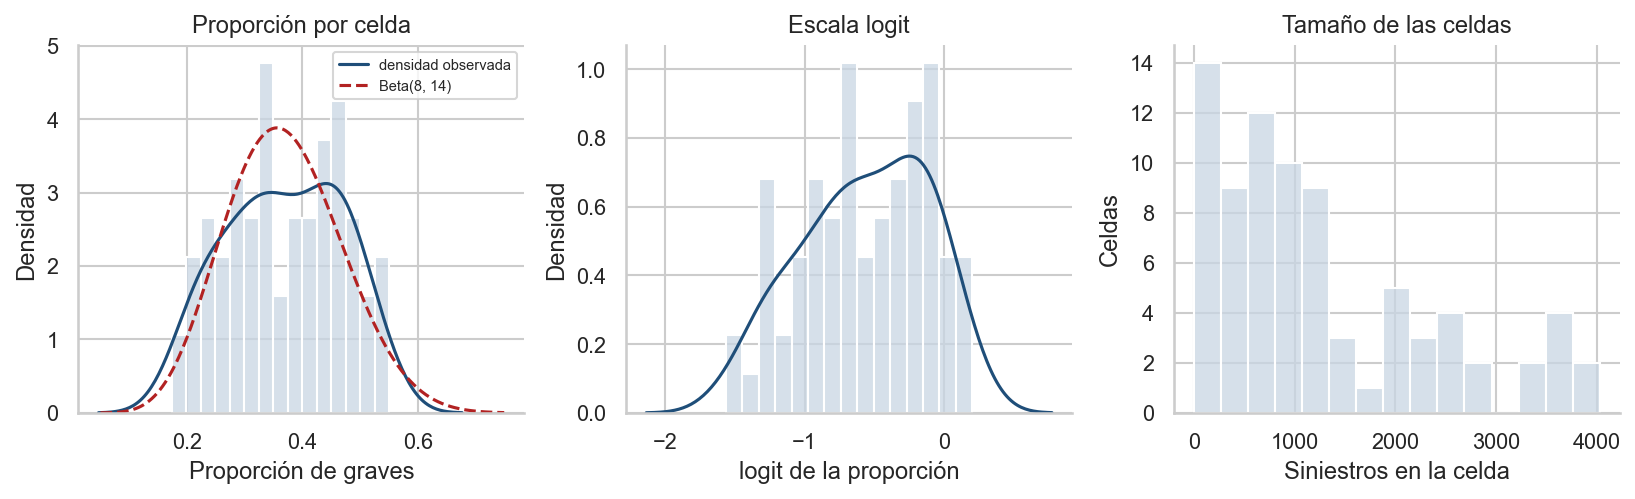

Celdas con n>=30: 75 | media 0.369 | desviación entre celdas 0.100 | rango 0.173-0.550
Beta por momentos: Beta(8.2, 14.0), concentración cercana a 22


In [4]:
cel_aj = ajuste_df.groupby(['localidad', 'franja'], observed=False).agg(n=('grave', 'size'), graves=('grave', 'sum')).reset_index()
c30 = cel_aj[cel_aj.n >= 30].copy()
c30['prop'] = c30.graves / c30.n
c30['logit'] = np.log(c30.prop / (1 - c30.prop))
media, var = c30.prop.mean(), c30.prop.var()
k_mom = media * (1 - media) / var - 1
a_mom, b_mom = media * k_mom, (1 - media) * k_mom

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
sns.histplot(c30.prop, bins=15, stat='density', color='#c9d6e3', ax=axes[0])
sns.kdeplot(c30.prop, color='#1f4e79', ax=axes[0], clip=(0, 1), label='densidad observada')
x = np.linspace(0.05, 0.75, 300)
axes[0].plot(x, stats.beta(a_mom, b_mom).pdf(x), color='#b22222', ls='--', label=f'Beta({a_mom:.0f}, {b_mom:.0f})')
axes[0].set_xlabel('Proporción de graves'); axes[0].set_ylabel('Densidad'); axes[0].legend(fontsize=7); axes[0].set_title('Proporción por celda')
sns.histplot(c30.logit, bins=15, stat='density', color='#c9d6e3', ax=axes[1])
sns.kdeplot(c30.logit, color='#1f4e79', ax=axes[1])
axes[1].set_xlabel('logit de la proporción'); axes[1].set_ylabel('Densidad'); axes[1].set_title('Escala logit')
sns.histplot(cel_aj.n, bins=15, color='#c9d6e3', ax=axes[2])
axes[2].set_xlabel('Siniestros en la celda'); axes[2].set_ylabel('Celdas'); axes[2].set_title('Tamaño de las celdas')
plt.tight_layout(); plt.savefig('figs/fig3_histogramas.pdf'); plt.show()
print(f'Celdas con n>=30: {len(c30)} | media {media:.3f} | desviación entre celdas {np.sqrt(var):.3f} | rango {c30.prop.min():.3f}-{c30.prop.max():.3f}')
print(f'Beta por momentos: Beta({a_mom:.1f}, {b_mom:.1f}), concentración cercana a {k_mom:.0f}')

**Qué vemos y qué decidimos.**
- La proporción por celda va de 17 % a 55 %. La Beta con la misma media y dispersión es una **aproximación razonable**, pero no perfecta: la densidad observada es más plana que la Beta entre 0,3 y 0,45 y tiene un pico hacia 0,47 que la Beta no captura. Esa forma es una pista de que hay grupos de celdas (por ejemplo, sur y noche); ver 4.3.
- En escala logit la distribución es más simétrica; esa es la escala del modelo M2 (logística jerárquica).
- Dentro de cada celda, el número de graves entre *n* siniestros es un conteo de sí/no: **Binomial**.

### 4.2 ¿Las celdas son distintas de verdad?

In [5]:
p_aj = c30.graves.sum() / c30.n.sum()
chi2 = (((c30.graves - c30.n * p_aj) ** 2) / (c30.n * p_aj * (1 - p_aj))).sum()
gl = len(c30) - 1
print(f'Chi-cuadrado = {chi2:,.0f} con {gl} grados de libertad (si fuera azar, estaría cerca de {gl})')

Chi-cuadrado = 4,648 con 74 grados de libertad (si fuera azar, estaría cerca de 74)


**Qué vemos.** El valor es unas 60 veces lo esperado por azar: las celdas son distintas. Esto descarta una sola probabilidad para toda la ciudad. **Ojo:** esta prueba dice que las celdas difieren, no que sean intercambiables; eso se revisa a continuación.

### 4.3 ¿Las diferencias tienen estructura?
Si las celdas fueran intercambiables, saber la localidad o la franja no diría nada sobre su severidad. Lo comprobamos ajustando una regresión logística con efectos aditivos de localidad y franja (sin interacción) y midiendo qué parte de la diferencia entre celdas explica (devianza explicada).

In [6]:
cc = cel_aj[cel_aj.n > 0].copy()
X = pd.get_dummies(cc[['localidad', 'franja']].astype(str), drop_first=True).astype(float)
X.insert(0, 'intercepto', 1.0); Xv = X.values
y, n = cc.graves.values, cc.n.values
beta = np.zeros(Xv.shape[1])
for _ in range(50):                          # mínimos cuadrados reponderados (cómo se ajusta una logística)
    eta = Xv @ beta; mu = 1 / (1 + np.exp(-eta)); W = n * mu * (1 - mu)
    z = eta + (y - n * mu) / np.clip(W, 1e-9, None)
    beta = np.linalg.solve(Xv.T @ (Xv * W[:, None]), Xv.T @ (W * z))
mu = 1 / (1 + np.exp(-Xv @ beta))

def devianza(y, n, mu):
    t1 = np.where(y > 0, y * np.log(np.where(y > 0, y / (n * mu), 1)), 0)
    t2 = np.where(n - y > 0, (n - y) * np.log(np.where(n - y > 0, (n - y) / (n * (1 - mu)), 1)), 0)
    return 2 * (t1 + t2).sum()

D_nula = devianza(y, n, np.full(len(cc), y.sum() / n.sum()))
D_aditiva = devianza(y, n, mu)
print(f'Devianza explicada por localidad + franja: {1 - D_aditiva / D_nula:.1%}')
print(f'Devianza que queda: {D_aditiva:,.0f} con {len(cc) - Xv.shape[1]} grados de libertad')

Devianza explicada por localidad + franja: 94.9%
Devianza que queda: 240 con 54 grados de libertad


**Qué vemos y qué decidimos.** Localidad y franja juntas, sin interacción, explican cerca del 95 % de la diferencia entre celdas. Es decir, las celdas **no** son intercambiables: hay estructura (una localidad del sur tiende a ser severa en todas sus franjas, y la noche es severa en casi todas las localidades). Lo que sobra es poco, pero más de lo que daría el azar, así que puede haber algo de interacción.

Por eso:
- **M1 (Beta-Binomial jerárquico)** queda como **modelo de partida**: es el más simple, se puede programar a mano con Gibbs y Metropolis–Hastings, y sirve de referencia.
- **M2 (logística jerárquica con localidad, franja, interacción y año)** es la respuesta a esta estructura y el candidato principal para el resultado final.

## 5. Priors y chequeo predictivo a priori

| Pieza | Prior | En palabras |
|---|---|---|
| m | Beta(2, 4) | Severidad típica de la ciudad. Centrada en 33 %, acepta de 5 % a 72 %. Prior débil, informada por la literatura: Vergel-Tovar et al. (2020, tabla 1) reportan cerca de 30 % de siniestros con víctimas en vías arteriales de Bogotá, 2012–2016. **Ojo:** ese periodo se solapa con 2015–2016 de nuestra base, así que no es información totalmente independiente; por eso la prior se deja ancha. |
| κ | Gamma(2; 0,04) | Cuánto se parecen las celdas al promedio, leído como "cuántos siniestros presta la ciudad a cada celda". Media 50, rango de 6 a 140. |

### 5.1 Chequeo predictivo a priori
Se simulan ciudades usando solo las priors y **los tamaños reales de las celdas de 2015–2017**: se sortean m y κ, la severidad de cada celda y el número de graves con su *n* real. Luego se comparan con lo observado cuatro cosas que se pueden medir: la media, la diferencia típica entre celdas, el rango y el % de celdas por encima de 50 %. Si lo observado cae dentro de lo que simulan las priors, las priors no lo descartan.

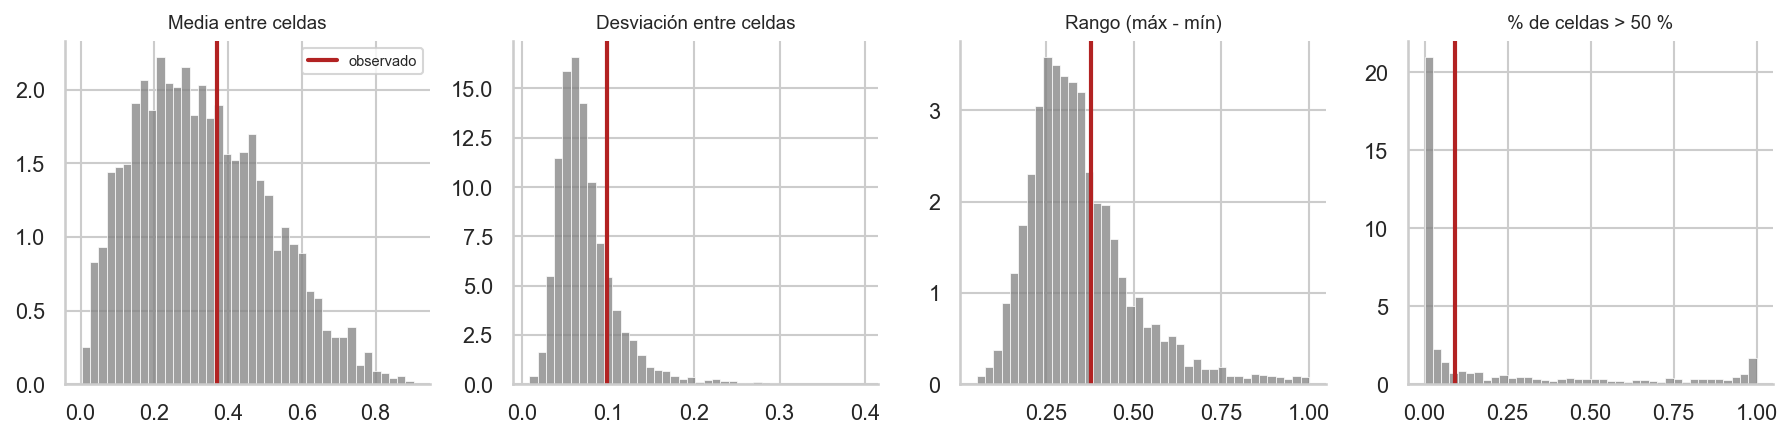

,observado,percentil en lo simulado,simulado 5 %,simulado 95 %
medida,,,,
Media entre celdas,0.369,0.607,0.074,0.650
Desviación entre celdas,0.099,0.826,0.034,0.140
Rango (máx - mín),0.377,0.674,0.159,0.631
% de celdas > 50 %,0.093,0.625,0.000,0.973


In [7]:
S_SIM = 4000
n_aj = cel_aj.n.values
m_sim = rng.beta(2, 4, S_SIM)
k_sim = rng.gamma(2, 1 / 0.04, S_SIM)
theta_sim = rng.beta(m_sim[:, None] * k_sim[:, None], (1 - m_sim[:, None]) * k_sim[:, None], size=(S_SIM, len(n_aj)))
y_sim = rng.binomial(n_aj, theta_sim)
mask = n_aj >= 30
p_sim = y_sim[:, mask] / n_aj[mask]
p_obs = (cel_aj.graves / cel_aj.n.replace(0, np.nan)).values[mask]

medidas = {'Media entre celdas': lambda a: a.mean(axis=-1), 'Desviación entre celdas': lambda a: a.std(axis=-1),
           'Rango (máx - mín)': lambda a: a.max(axis=-1) - a.min(axis=-1), '% de celdas > 50 %': lambda a: (a > 0.5).mean(axis=-1)}
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
filas = []
for ax, (nombre, f) in zip(axes, medidas.items()):
    sim, obs = f(p_sim), f(p_obs)
    sns.histplot(sim, ax=ax, color='grey', stat='density', bins=40)
    ax.axvline(obs, color='#b22222', lw=2, label='observado')
    ax.set_title(nombre, fontsize=9); ax.set_ylabel('')
    filas.append({'medida': nombre, 'observado': obs, 'percentil en lo simulado': np.mean(sim < obs),
                  'simulado 5 %': np.quantile(sim, 0.05), 'simulado 95 %': np.quantile(sim, 0.95)})
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig('figs/fig5_priors.pdf'); plt.show()
display(pd.DataFrame(filas).set_index('medida'))

**Qué vemos.** Las cuatro medidas observadas caen dentro del 90 % central de lo que simulan las priors (percentiles entre 0,6 y 0,85). Las priors permiten ciudades muy distintas pero no descartan la nuestra: es lo que se busca de una prior débil.

## 6. Preparación del entrenamiento y referencias de comparación
Se guardan los conteos por celda (y por celda y año, para el efecto de año de M2). Las referencias que el modelo debe superar en 2018–2019, todas fijadas en el Avance 2:
- **Agrupamiento completo:** una sola probabilidad para la ciudad.
- **Sin agrupamiento:** la proporción cruda de cada celda en 2015–2017.
- **Criterio actual:** ordenar por número de siniestros graves en 2015–2017.

Medidas: Brier y log-loss (más bajo es mejor), Spearman entre el orden de 2015–2017 y la proporción observada en 2018–2019 (criterio c del A2) y coincidencias en el top 10.

In [8]:
def a_celdas(df, por=('localidad', 'franja')):
    return df.groupby(list(por), observed=False).agg(n=('grave', 'size'), graves=('grave', 'sum')).reset_index()

ajuste = a_celdas(base[base.periodo == 'Ajuste 2015-2017'])
prueba = a_celdas(base[base.periodo == 'Prueba 2018-2019'])
por_anio_celda = a_celdas(base, ('localidad', 'franja', 'anio'))
assert ajuste.n.sum() + prueba.n.sum() == len(base)
ajuste.to_csv(os.path.join(CARPETA_TRABAJADOS, 'celdas_ajuste_2015_2017.csv'), index=False)
prueba.to_csv(os.path.join(CARPETA_TRABAJADOS, 'celdas_prueba_2018_2019.csv'), index=False)
por_anio_celda.to_csv(os.path.join(CARPETA_TRABAJADOS, 'celdas_por_anio_2015_2019.csv'), index=False)

p_ciudad = ajuste.graves.sum() / ajuste.n.sum()
prop_cruda = (ajuste.graves / ajuste.n.replace(0, np.nan)).fillna(p_ciudad).clip(1e-3, 1 - 1e-3)

def brier(p, cp):
    y, n = cp.graves, cp.n
    return ((y * (1 - p) ** 2 + (n - y) * p ** 2).sum()) / n.sum()

def logloss(p, cp):
    y, n = cp.graves, cp.n
    return -((y * np.log(p) + (n - y) * np.log(1 - p)).sum()) / n.sum()

ok = (ajuste.n >= 30) & (prueba.n >= 30)
p_prueba = prueba.graves / prueba.n
top_real = set(p_prueba[ok].nlargest(10).index)
ref = pd.DataFrame({
    'Brier': [brier(p_ciudad, prueba), brier(prop_cruda.values, prueba), np.nan],
    'Log-loss': [logloss(p_ciudad, prueba), logloss(prop_cruda.values, prueba), np.nan],
    'Spearman con 2018-2019': [np.nan, stats.spearmanr(prop_cruda[ok], p_prueba[ok]).statistic,
                               stats.spearmanr(ajuste.graves[ok], p_prueba[ok]).statistic],
    'Coincidencias top 10': [np.nan, len(set(prop_cruda[ok].nlargest(10).index) & top_real),
                             len(set(ajuste.graves[ok].nlargest(10).index) & top_real)]},
    index=['Agrupamiento completo (ciudad)', 'Sin agrupamiento (proporción cruda)', 'Criterio actual (conteo de graves)'])
print(f'Severidad media en ajuste: {p_ciudad:.3f} | en prueba: {prueba.graves.sum() / prueba.n.sum():.3f}')
display(ref.round(4))

Severidad media en ajuste: 0.328 | en prueba: 0.361


,Brier,Log-loss,Spearman con 2018-2019,Coincidencias top 10
Agrupamiento completo (ciudad),0.232,0.656,NaN,NaN
Sin agrupamiento (proporción cruda),0.222,0.635,0.921,6.000
Criterio actual (conteo de graves),NaN,NaN,-0.329,0.000


**Qué vemos.** El orden por conteo de graves va **en contra** de la severidad de 2018–2019 (Spearman negativo, ninguna coincidencia en el top 10): señala las zonas con más tráfico, no las más severas. La proporción cruda ordena bien las celdas grandes (Spearman cercano a 0,9) pero falla en las pequeñas. El modelo jerárquico tiene que ordenar al menos tan bien como la proporción cruda y predecir mejor (Brier y log-loss más bajos).

## Celdas del informe final

In [9]:
os.chdir(BASE)
R = dict(celdas=L * F, con_datos=int((n_tr > 0).sum()), evaluables=int(eleg.sum()),
         pequenas_menos_500=int((n_tr < 500).sum()), n_ajuste=int(n_tr.sum()), graves_ajuste=int(y_tr.sum()),
         n_prueba=int(n_te.sum()), graves_prueba=int(y_te.sum()),
         p_ajuste=y_tr.sum() / n_tr.sum(), p_prueba=y_te.sum() / n_te.sum(), p_2020=d20.grave.mean())
print(limpio(R))
guardar_json(R, '03_celdas.json')

{'celdas': 80, 'con_datos': 77, 'evaluables': 75, 'pequenas_menos_500': 21, 'n_ajuste': 101500, 'graves_ajuste': 33331, 'n_prueba': 71943, 'graves_prueba': 25972, 'p_ajuste': 0.32838, 'p_prueba': 0.36101, 'p_2020': 0.39324}
Guardado: C:\Users\dddan\Downloads\Pensamiento - Bayesiana\4. Estadística Bayesiana\Proyecto\4. Entrega final\notebooks\salidas\resultados\03_celdas.json
